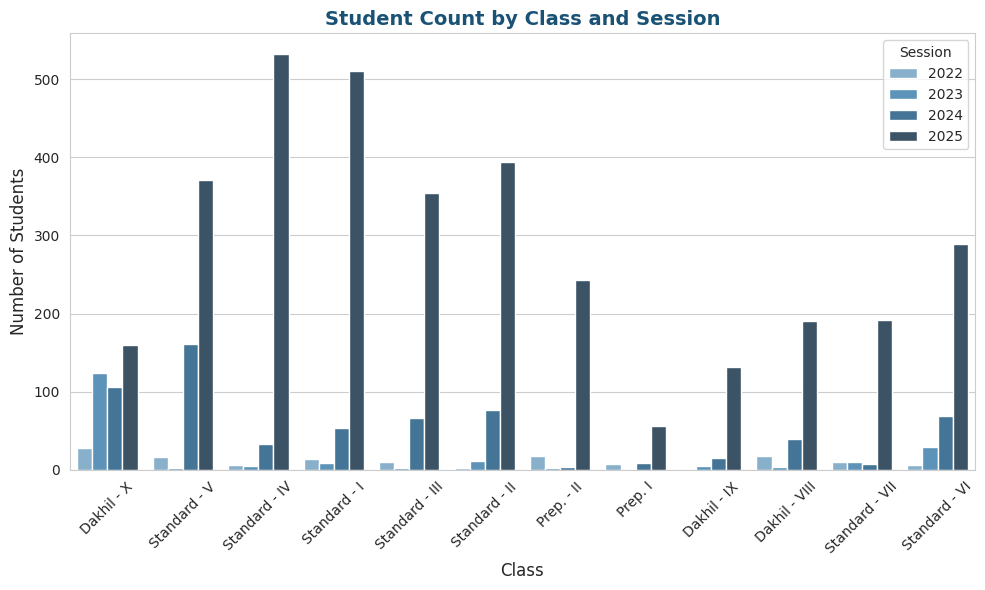

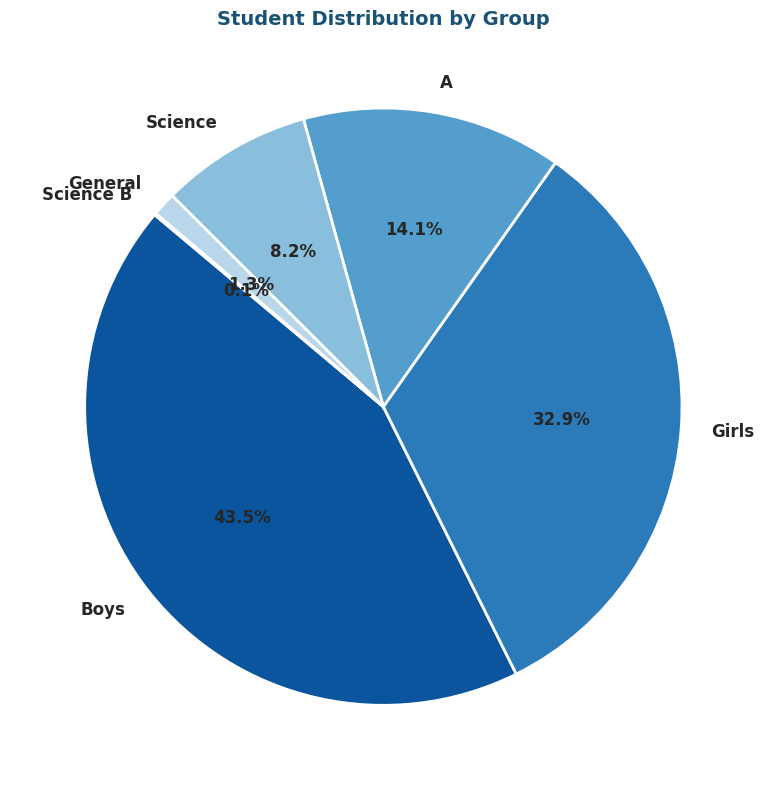

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# CSV ফাইল লোড করা
try:
    df = pd.read_csv('/kaggle/input/exam-admit-card-dataset/data.csv')
except FileNotFoundError:
    print("Error: data.csv not found. Please check the file path.")
    exit()

# Clean style
sns.set_style("whitegrid")

# ===============================
# ১. Class-wise Student Count
# ===============================

plt.figure(figsize=(10, 6))

# Unique session বের করা
sessions = df['session'].unique()

# Session সংখ্যার উপর ভিত্তি করে Blue palette তৈরি
blue_palette = sns.color_palette("Blues_d", n_colors=len(sessions))

sns.countplot(
    data=df,
    x='class',
    hue='session',
    palette=blue_palette
)

plt.title('Student Count by Class and Session',
          fontsize=14,
          fontweight='bold',
          color='#1a5276')

plt.xlabel('Class', fontsize=12)
plt.ylabel('Number of Students', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Session', frameon=True)
plt.tight_layout()
plt.show()


# ===============================
# ২. Group-wise Distribution
# ===============================

plt.figure(figsize=(8, 8))

groups = df['group'].unique()
blue_colors = sns.color_palette("Blues_r", n_colors=len(groups))

df['group'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    colors=blue_colors,
    startangle=140,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)

plt.title('Student Distribution by Group',
          fontsize=14,
          fontweight='bold',
          color='#1a5276')

plt.ylabel('')
plt.tight_layout()
plt.show()


/tmp/ipykernel_55/3624450699.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


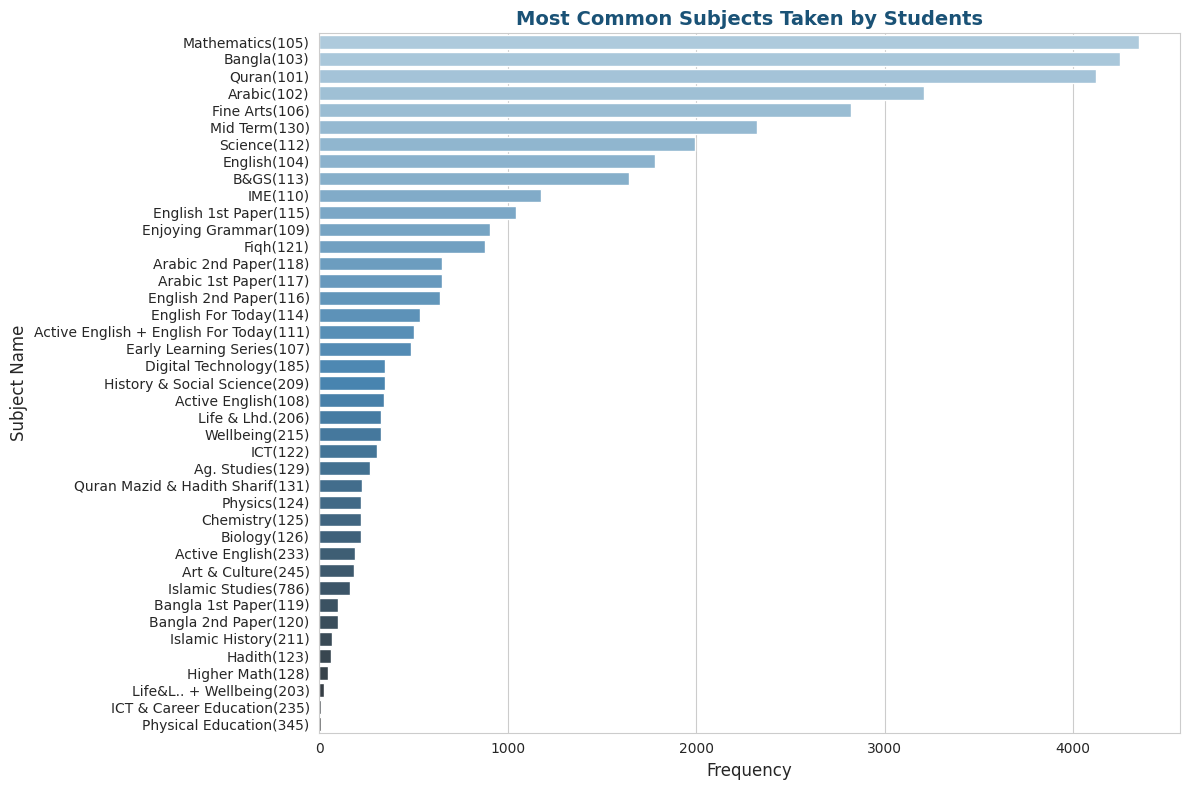

In [8]:
# 'subjects' কলামকে স্প্লিট করে আলাদা আলাদা রো-তে নেওয়া
subject_series = df['subjects'].str.split(', ').explode()

# যদি subject name থেকে কোড remove করতে চান (ঐচ্ছিক)
# subject_series = subject_series.str.replace(r"\(.*\)", "", regex=True)

# Count বের করা
subject_counts = subject_series.value_counts()

plt.figure(figsize=(12, 8))

# Dynamic Blue gradient palette তৈরি
blue_palette = sns.color_palette("Blues_d", n_colors=len(subject_counts))

# Horizontal bar plot
sns.barplot(
    x=subject_counts.values,
    y=subject_counts.index,
    palette=blue_palette
)

plt.title('Most Common Subjects Taken by Students',
          fontsize=14,
          fontweight='bold',
          color='#1a5276')

plt.xlabel('Frequency', fontsize=12)
plt.ylabel('Subject Name', fontsize=12)

plt.tight_layout()
plt.show()


In [ ]:
# প্রতিটি রো এর জন্য সাবজেক্ট সংখ্যা গণনা করা
df['subject_count'] = df['subjects'].apply(lambda x: len(str(x).split(',')))

plt.figure(figsize=(8, 5))
sns.histplot(df['subject_count'], bins=10, kde=True, color='orange')
plt.title('Distribution of Subject Count per Student')
plt.xlabel('Number of Subjects')
plt.ylabel('Student Count')
plt.show()

In [ ]:
# ক্লাস এবং গ্রুপের ক্রসবিন্যাস (Cross-tabulation)
ct = pd.crosstab(df['class'], df['group'])

plt.figure(figsize=(10, 6))
sns.heatmap(ct, annot=True, cmap='YlGnBu', fmt='d')
plt.title('Student Concentration: Class vs Group')
plt.show()

In [ ]:
# এটি ছোট ছোট সাব-প্লট তৈরি করবে যা দিয়ে আপনি একসাথে অনেক ডাইমেনশন দেখতে পাবেন
g = sns.catplot(
    data=df, x="class", col="session", row="semester",
    hue="group", kind="count", height=4, aspect=1.2
)
g.set_xticklabels(rotation=45)
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Student Count breakdown by Class, Session, Semester, and Group')
plt.show()

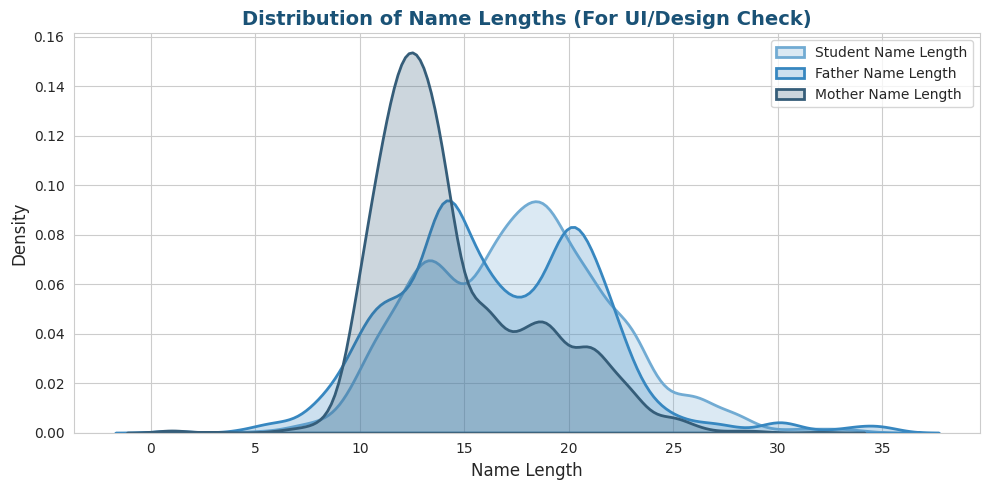

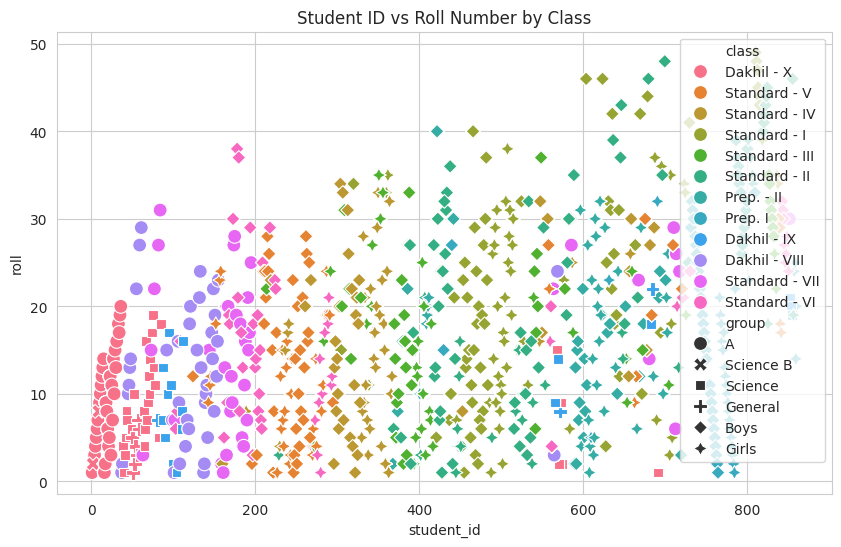

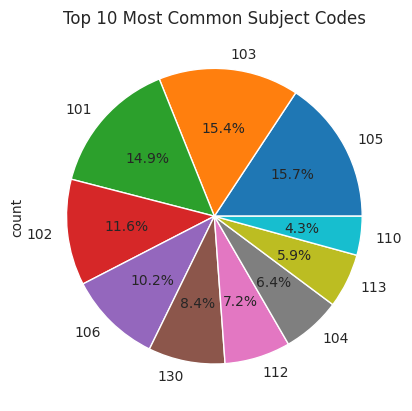

In [4]:
# --- ১. স্টুডেন্ট ও বাবা-মায়ের নামের দৈর্ঘ্যের তুলনা ---

df['name_len'] = df['student_name'].str.len()
df['f_name_len'] = df['father_name'].str.len()
df['m_name_len'] = df['mother_name'].str.len()

plt.figure(figsize=(10, 5))

# Blue gradient palette তৈরি (৩টা shade)
blue_shades = sns.color_palette("Blues_d", 3)

sns.kdeplot(
    df['name_len'],
    label='Student Name Length',
    fill=True,
    color=blue_shades[0],
    linewidth=2
)

sns.kdeplot(
    df['f_name_len'],
    label='Father Name Length',
    fill=True,
    color=blue_shades[1],
    linewidth=2
)

sns.kdeplot(
    df['m_name_len'],
    label='Mother Name Length',
    fill=True,
    color=blue_shades[2],
    linewidth=2
)

plt.title('Distribution of Name Lengths (For UI/Design Check)',
          fontsize=14,
          fontweight='bold',
          color='#1a5276')

plt.xlabel('Name Length', fontsize=12)
plt.ylabel('Density', fontsize=12)

plt.legend(frameon=True)
plt.tight_layout()
plt.show()




# --- ৩. স্টুডেন্ট আইডির সাথে রোলের সম্পর্ক (Scatter Plot) ---
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='student_id', y='roll', hue='class', style='group', s=100)
plt.title('Student ID vs Roll Number by Class')
plt.show()

# --- ৪. সাবজেক্ট কোড এক্সট্রাকশন (Subject Code Analysis) ---
# এটি 'Bangla(103)' থেকে শুধু '103' বের করে আনবে
import re
all_codes = []
for sub_list in df['subjects']:
    codes = re.findall(r'\((.*?)\)', str(sub_list))
    all_codes.extend(codes)

pd.Series(all_codes).value_counts().head(10).plot(kind='pie', autopct='%1.1f%%')
plt.title('Top 10 Most Common Subject Codes')
plt.show()